In [1]:
import pandas as pd
import scipy.io
import scipy.sparse as sp
import numpy as np
import anndata as ad
import scanpy as sc
import celloracle as co

# ── 1. Load peaks ──────────────────────────────────────────────────────────────
peaks = pd.read_csv("peaks.txt", header=None)[0].astype(str).str.strip().values
# drop header row if present
if peaks[0].lower() in ["x", "v1", ""]:
    peaks = peaks[1:]

print(f"Peaks: {len(peaks)}")
print(peaks[:3])

Peaks: 122253
['chr1-237511-238011' 'chr1-752456-752956' 'chr1-773621-774121']


In [2]:
# ── 2. Load peak × TF motif matrix ─────────────────────────────────────────────
motif_mat = scipy.io.mmread("peak_tf.mtx").tocsr()   # shape: peaks × TFs
tf_names = open("tf_names.txt").read().strip().split()

print(f"Motif matrix shape: {motif_mat.shape}")   # expect (n_peaks, n_tfs)
print(f"TF names: {len(tf_names)}")

# Sanity-check orientation — flip if needed
if motif_mat.shape[0] == len(tf_names) and motif_mat.shape[1] == len(peaks):
    motif_mat = motif_mat.T   # make it peaks × TFs
    print("Transposed to (peaks × TFs)")

assert motif_mat.shape[0] == len(peaks),  f"Row mismatch: {motif_mat.shape[0]} vs {len(peaks)}"
assert motif_mat.shape[1] == len(tf_names), f"Col mismatch: {motif_mat.shape[1]} vs {len(tf_names)}"

Motif matrix shape: (122253, 633)
TF names: 633


In [3]:
# ── 3. Load peak → gene links ───────────────────────────────────────────────────
peak_gene = pd.read_csv("peak_gene.csv", sep="\t")[["peak", "gene"]]
peak_gene = peak_gene.dropna()
print(f"Peak-gene links: {len(peak_gene)}")
print(peak_gene.head())

# ── 4. Build one-hot TF matrix as a DataFrame (peaks × TFs) ────────────────────
# Binarize (any score > 0 → 1, matching the threshold=10 logic you used before,
# OR keep as-is if your mtx is already binary/scored)
motif_binary = (motif_mat > 0).astype(np.float32)

peak_tf_df = pd.DataFrame.sparse.from_spmatrix(
    motif_binary,
    index=peaks,
    columns=tf_names
)

# ── 5. Merge with peak→gene to get the base GRN ────────────────────────────────
# peak_gene "peak" column must match the peaks index
# Common format mismatch: peaks.txt uses "chr1-start-end", peak_gene may use "chr1:start-end"
# Check and fix:
print("\nPeak format in peaks.txt:", peaks[0])
print("Peak format in peak_gene.csv:", peak_gene["peak"].iloc[0])

Peak-gene links: 116521
                 peak            gene
0  chr1-237511-238011      AP006222.2
1  chr1-752456-752956  RP11-206L10.10
2  chr1-773621-774121       LINC01128
3  chr1-805029-805529          FAM41C
4  chr1-825947-826447      AL645608.2

Peak format in peaks.txt: chr1-237511-238011
Peak format in peak_gene.csv: chr1-237511-238011


In [4]:
# ── 6. Normalize peak strings to underscore format (chr_start_end) ─────────────
def normalize_peak(p):
    """Convert chr1-100-200 or chr1:100-200 → chr1_100_200"""
    return str(p).replace(":", "_").replace("-", "_")

peak_gene["peak_norm"] = peak_gene["peak"].apply(normalize_peak)
peak_tf_df.index = [normalize_peak(p) for p in peak_tf_df.index]

# Keep only peaks present in both
shared_peaks = set(peak_tf_df.index) & set(peak_gene["peak_norm"])
print(f"Shared peaks: {len(shared_peaks)} / {len(peaks)} total")

peak_tf_df = peak_tf_df.loc[peak_tf_df.index.isin(shared_peaks)]
peak_gene_filt = peak_gene[peak_gene["peak_norm"].isin(shared_peaks)].copy()

Shared peaks: 116521 / 122253 total


In [5]:
# ── 7. Merge peak-TF with peak-gene ────────────────────────────────────────────
peak_tf_reset = peak_tf_df.reset_index().rename(columns={"index": "peak_norm"})

base_grn = peak_gene_filt[["peak_norm", "gene"]].merge(
    peak_tf_reset, on="peak_norm", how="inner"
)

# Rename to match CellOracle convention (from your working CLL pipeline)
base_grn = base_grn.rename(columns={"peak_norm": "peak_id", "gene": "gene_short_name"})

print(f"Base GRN shape: {base_grn.shape}")
print(base_grn.iloc[:3, :8])  # peek at first few cols

# Save
base_grn.to_csv("celloracle_base_grn_hematopoiesis.csv", index=False)
print("Saved!")

Base GRN shape: (116521, 635)
              peak_id gene_short_name  FOXF2  FOXD1  IRF2  MZF1(var.2)  \
0  chr1_237511_238011      AP006222.2    0.0    0.0   0.0          0.0   
1  chr1_752456_752956  RP11-206L10.10    0.0    0.0   0.0          0.0   
2  chr1_773621_774121       LINC01128    0.0    0.0   0.0          0.0   

   MAX::MYC  PPARG  
0       0.0    0.0  
1       0.0    0.0  
2       0.0    0.0  
Saved!


In [6]:
# ── 8. Load your RNA AnnData ────────────────────────────────────────────────────
adata = sc.read_h5ad("velten_rna.h5ad")
print(adata)

# Make sure raw counts are in .X
# adata.X = adata.layers['counts'].copy()   # uncomment if needed

# ── 9. Initialize Oracle ────────────────────────────────────────────────────────
oracle = co.Oracle()

oracle.import_anndata_as_raw_count(
    adata=adata,
    cluster_column_name="YOUR_CLUSTER_COLUMN",   # ← change this
    embedding_name="X_umap"                       # ← change if different
)

oracle.import_TF_data(TF_info_matrix=base_grn)
print("Oracle initialized!")

AnnData object with n_obs × n_vars = 1035 × 12553
    obs: 'plate', 'well', 'facs_fsc.area', 'facs_fsc_height', 'facs_ssc.area', 'facs_ssc_height', 'facs_cd45ra', 'facs_cd135', 'facs_cd90', 'facs_cd49f', 'facs_lin', 'facs_cd34', 'facs_cd38', 'facs_cd10', 'culture_key', 'culture_cells_in_colony', 'culture_mk_cd41+', 'culture_ery_cd235+', 'culture_total_number_of_my_cd33+', 'facs_pseudotime', 'fate_stemness', 'n_genes', 'dpt_pseudotime'
    var: 'n_cells'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    layers: 'counts'
12553 genes were found in the adata. Note that Celloracle is intended to use around 1000-3000 genes, so the behavior with this number of genes may differ from what is expected.


KeyError: 'Could not find key YOUR_CLUSTER_COLUMN in .var_names or .obs.columns.'

In [15]:
!pip install --user scikit-misc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 60.5 MB/s eta 0:00:00


In [13]:
import numpy as np

print("Min:", np.min(adata.X))
print("Max:", np.max(adata.X))
print("Any inf:", np.isinf(adata.X.A).any())
print("Any nan:", np.isnan(adata.X.A).any())


Min: 0.0
Max: 78783.0
Any inf: False
Any nan: False


In [17]:
import scanpy as sc

adata.X = adata.layers["counts"].copy()

sc.pp.highly_variable_genes(
    adata,
    n_top_genes=3000,
    flavor="seurat_v3"
)

# 2. Build mask BEFORE subsetting
tf_set = set(tf_names)

hvg_mask = adata.var["highly_variable"].values
tf_mask  = adata.var_names.isin(tf_set)

keep = hvg_mask | tf_mask

# 3. Subset ONCE
adata = adata[:, keep].copy()

sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

sc.tl.pca(adata)
adata.uns.pop("diffmap_evals", None)
adata.obsm.pop("X_diffmap", None)

sc.pp.neighbors(adata)

sc.tl.leiden(adata, resolution=0.5, key_added="leiden")

sc.tl.umap(adata)
sc.pl.umap(adata, color=["leiden", "facs_cd34", "facs_cd38"])

adata.X = adata.layers["counts"].copy()

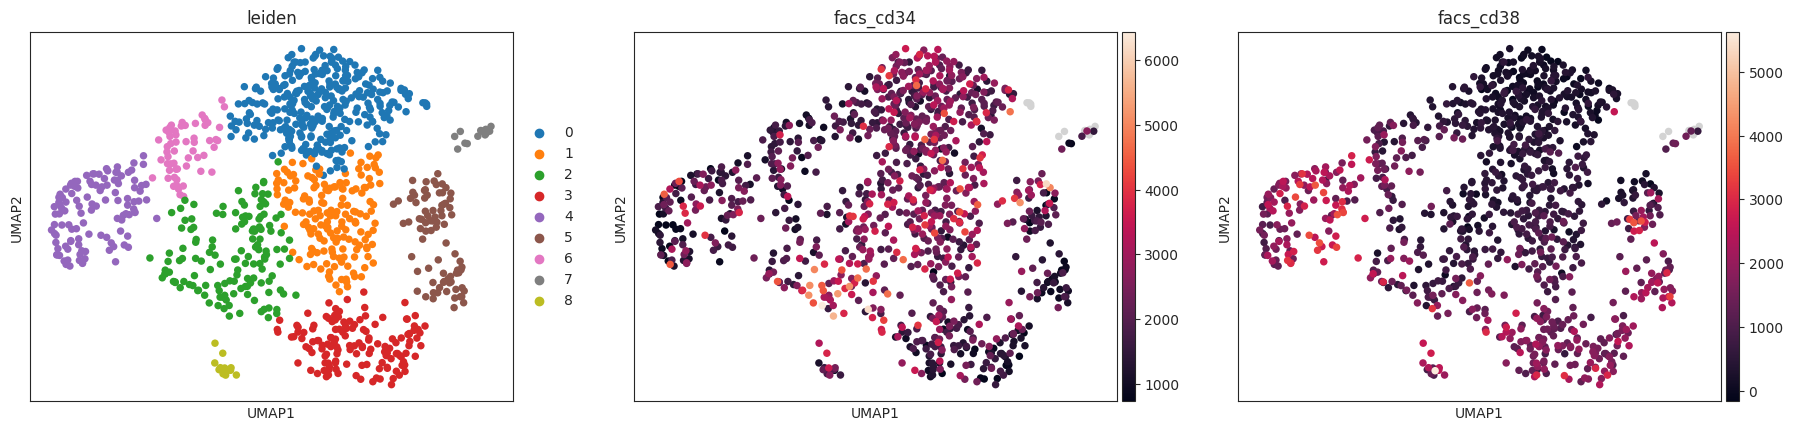

In [20]:
%matplotlib inline
sc.pl.umap(adata, color=["leiden", "facs_cd34", "facs_cd38"])

In [21]:
oracle = co.Oracle()

oracle.import_anndata_as_raw_count(
    adata=adata,
    cluster_column_name="leiden",   
    embedding_name="X_umap"
)

In [34]:
import pandas as pd

# load your base_grn
df = pd.read_csv("celloracle_base_grn_hematopoiesis.csv")

# identify TF columns
tf_cols = [c for c in df.columns if c not in ["peak_id", "gene_short_name"]]

# group by gene and take max (logical OR across peaks)
A_df = df.groupby("gene_short_name")[tf_cols].max().T

print(A_df.shape)
print(A_df.iloc[:5, :5])

(633, 21311)
gene_short_name  7SK  A1BG  A2M  A2ML1  A3GALT2
FOXF2            0.0   0.0  0.0    0.0      0.0
FOXD1            0.0   0.0  0.0    0.0      0.0
IRF2             1.0   0.0  1.0    0.0      0.0
MZF1(var.2)      0.0   1.0  0.0    0.0      0.0
MAX::MYC         0.0   0.0  0.0    0.0      1.0


In [37]:
common_genes = list(set(A_df.columns) & set(adata.var_names))

print("Overlap:", len(common_genes))

A_df = A_df[common_genes]
adata = adata[:, common_genes].copy()

Overlap: 2995


In [38]:
print("TF overlap:", len(set(A_df.index) & set(adata.var_names)))

TF overlap: 271


In [22]:
# ── 10. PCA + imputation ────────────────────────────────────────────────────────
oracle.perform_PCA()

n_comps = 30  # adjust from elbow plot
n_cell  = oracle.adata.shape[0]
k       = int(0.025 * n_cell)
print(f"k = {k}")

oracle.knn_imputation(
    n_pca_dims=n_comps, k=k,
    balanced=True, b_sight=k*8, b_maxl=k*4, n_jobs=4
)

oracle.to_hdf5("celloracle_hematopoiesis_imputed.celloracle.oracle")

k = 25


ValueError: Found No TF information. Please import TF data (base-GRN) first.

In [40]:
base_grn = pd.read_csv("celloracle_base_grn_hematopoiesis.csv")
oracle.import_TF_data(TF_info_matrix=base_grn)

# ── 11. Fit GRN ────────────────────────────────────────────────────────────────
links = oracle.get_links(
    cluster_name_for_GRN_unit="leiden",
    alpha=10,
    verbose_level=1
)
oracle.to_hdf5("celloracle_hematopoiesis_grn.celloracle.oracle")
links.to_hdf5("links_hematopoiesis.celloracle.links")

  0%|          | 0/9 [00:00<?, ?it/s]

In [42]:
print(dir(links))

['ALPHA_used', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_get_network_score_if_not_exist', '_pipeline', 'cluster', 'entropy', 'filter_links', 'get_network_entropy', 'get_network_score', 'get_score', 'links_dict', 'model_method', 'name', 'palette', 'plot_cartography_scatter_per_cluster', 'plot_cartography_term', 'plot_degree_distributions', 'plot_network_entropy_distributions', 'plot_score_comparison_2D', 'plot_score_discributions', 'plot_score_per_cluster', 'plot_scores_as_rank', 'to_hdf5']


In [43]:
import os
os.makedirs("grn_clusters", exist_ok=True)

for cluster, df in links.links_dict.items():
    df.to_csv(f"grn_clusters/cluster_{cluster}.csv", index=False)

In [46]:
import pandas as pd
import numpy as np

# collect all edges
dfs = []
for cluster, df in links.links_dict.items():
    df = df.copy()
    df["cluster"] = cluster
    dfs.append(df)

all_links = pd.concat(dfs)

# average coefficients across clusters
A_df = (
    all_links
    .groupby(["source", "target"])["coef_mean"]
    .mean()
    .reset_index()
)

# pivot to matrix
A_mat = A_df.pivot(index="source", columns="target", values="coef_mean").fillna(0)

# save
np.save("A_celloracle.npy", A_mat.values)

# also save names (VERY IMPORTANT)
np.save("A_genes.npy", A_mat.columns.values)
np.save("A_tfs.npy", A_mat.index.values)

print("Saved A_celloracle.npy:", A_mat.shape)

Saved A_celloracle.npy: (277, 2995)


In [48]:
import os

os.makedirs("A_matrices", exist_ok=True)

for cluster, df in links.links_dict.items():
    mat = df.pivot(index="source", columns="target", values="coef_mean").fillna(0)
    np.save(f"A_matrices/A_cluster_{cluster}.npy", mat.values)
    np.save(f"A_matrices/A_cluster_{cluster}_genes.npy", mat.columns.values)
    np.save(f"A_matrices/A_cluster_{cluster}_tfs.npy", mat.index.values)

In [45]:
for cluster, df in links.links_dict.items():
    print(cluster)
    print(df.columns)
    break

0
Index(['source', 'target', 'coef_mean', 'coef_abs', 'p', '-logp'], dtype='object')


In [47]:
print(list(links.links_dict.keys()))

['0', '1', '2', '3', '4', '5', '6', '7', '8']
